# Propagate one heat mode in two directions
Run with OneSimulation, NumPy and Matplotlib installed.
Double the spatial resolution while holding the final time fixed. Keep the grid-dependent reference in the comparison.

Finest-grid temporal order: 2.0003


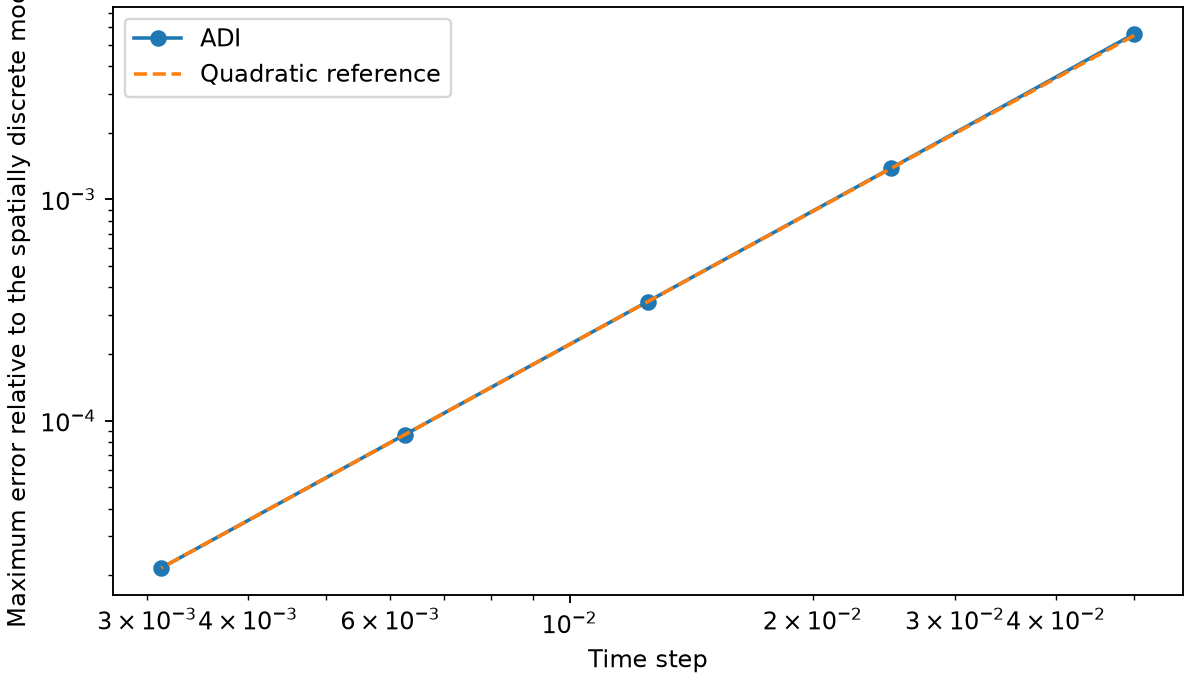

In [1]:
"""Measure the temporal order of an ADI heat step against an exact grid mode."""
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.linear.matrices.dense_linear_algebra import solve_dense

m = 9
spacing = 1/(m+1)
d = (np.diag(-2*np.ones(m)) + np.diag(np.ones(m-1), 1) + np.diag(np.ones(m-1), -1))/spacing**2
sine = np.sin(np.pi*spacing*np.arange(1, m+1))
initial = np.outer(sine, sine)
decay = -4*np.sin(np.pi*spacing/2)**2/spacing**2
end = 0.1
ref = initial*np.exp(2*decay*end)
steps, errors = np.array([2, 4, 8, 16, 32]), []
for count in steps:
    plus, minus = np.eye(m) + end*d/(2*count), np.eye(m) - end*d/(2*count)
    state = initial.copy()
    for _ in range(count):
        half = solve_dense(minus, state @ plus)
        state = solve_dense(minus, (plus @ half).T).T
    errors.append(np.max(abs(state-ref)))
orders = np.log2(np.array(errors[:-1])/errors[1:])
print(f"Finest-grid temporal order: {orders[-1]:.4f}")
assert abs(orders[-1]-2) < 0.01
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.loglog(end/steps, errors, "o-", label="ADI")
ax.loglog(end/steps, errors[-1]*(steps[-1]/steps)**2, "--", label="Quadratic reference")
ax.set(xlabel="Time step", ylabel="Maximum error relative to the spatially discrete mode")
ax.legend()
fig.savefig("numerics-adi-heat.png", dpi=170)
